In [2]:
from pathlib import Path
import pandas as pd

In [3]:
raw_data = Path('../data/raw')
recs = pd.read_csv(raw_data/'recommendations.csv', usecols=["user_id", "app_id", "date", "is_recommended", "hours"], 
                   parse_dates=["date"])
games = pd.read_csv(raw_data / "games.csv")

print(recs.shape, games.shape)
print(recs.dtypes)
print(recs.isna().sum())
print(recs.head())

(41154794, 5) (50872, 13)
app_id                     int64
date              datetime64[us]
is_recommended              bool
hours                    float64
user_id                    int64
dtype: object
app_id            0
date              0
is_recommended    0
hours             0
user_id           0
dtype: int64
    app_id       date  is_recommended  hours  user_id
0   975370 2022-12-12            True   36.3    51580
1   304390 2017-02-17           False   11.5     2586
2  1085660 2019-11-17            True  336.5   253880
3   703080 2022-09-23            True   27.4   259432
4   526870 2021-01-10            True    7.9    23869


In [4]:
audit = {
"rows": len(recs),
"missing_hours": int(recs["hours"].isna().sum()),
"duplicate_pairs": int(recs.duplicated(["user_id", "app_id"]).sum()),
"min_hours": float(recs["hours"].min()),
"max_hours": float(recs["hours"].max()),
}
print(audit)

{'rows': 41154794, 'missing_hours': 0, 'duplicate_pairs': 21, 'min_hours': 0.0, 'max_hours': 1000.0}


In [5]:
out = Path('../data/processed/chunks')
out.mkdir(parents=True, exist_ok=True)

cols = ["user_id", "app_id", "date", "is_recommended", "hours"]
for idx, chunk in enumerate(pd.read_csv(
"../data/raw/recommendations.csv", usecols=cols,
parse_dates=["date"], chunksize=500_000)):
    chunk = chunk.dropna(subset=["user_id", "app_id", "date"])
    chunk = chunk[chunk["hours"].ge(0) & chunk["hours"].notna()]
    chunk.to_parquet(out / f"part-{idx:04d}.parquet", index=False)

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
print("cwd:", Path.cwd(), "| project root:", ROOT)

import pandas as pd
from src import preprocessing as pp
from src.utils import RAW_DIR, RESULTS_DIR, df_memory_mb, save_json
pd.set_option("display.max_columns", 50)

cwd: /Users/alina/Desktop/Programming for AI/AI_programming_final_project/notebooks | project root: /Users/alina/Desktop/Programming for AI/AI_programming_final_project


In [7]:
pp.check_raw_files()

,dataset,file,exists,size_mb
0,recommendations,recommendations.csv,True,1929.5
1,games,games.csv,True,4.6
2,users,users.csv,True,184.1
3,metadata,games_metadata.json,True,16.7


In [8]:
reviews = pp.load_recommendations_sample(n_rows=100_000)
print("shape:", reviews.shape, "| memory: %.1f MB" % df_memory_mb(reviews))
print(reviews.dtypes)
reviews.head()

shape: (100000, 8) | memory: 5.4 MB
app_id                     int64
helpful                    int64
funny                      int64
date              datetime64[us]
is_recommended              bool
hours                    float64
user_id                    int64
review_id                  int64
dtype: object


,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
0,975370,0,0,2022-12-12,True,36.3,51580,0
1,304390,4,0,2017-02-17,False,11.5,2586,1
2,1085660,2,0,2019-11-17,True,336.5,253880,2
3,703080,0,0,2022-09-23,True,27.4,259432,3
4,526870,0,0,2021-01-10,True,7.9,23869,4


In [9]:
pp.describe_dataframe(reviews)

,column,dtype,missing,missing_pct,n_unique,example
0,app_id,int64,0,0.0,208,975370
1,helpful,int64,0,0.0,434,0
2,funny,int64,0,0.0,250,0
3,date,datetime64[us],0,0.0,3518,2022-12-12 00:00:00
4,is_recommended,bool,0,0.0,2,True
5,hours,float64,0,0.0,9531,36.3
6,user_id,int64,0,0.0,98803,51580
7,review_id,int64,0,0.0,100000,0


In [10]:
games = pp.load_games()
print("games:", games.shape)
display(pp.describe_dataframe(games))
games.head()

games: (50872, 13)


,column,dtype,missing,missing_pct,n_unique,example
0,app_id,int64,0,0.0,50872,13500
1,title,str,0,0.0,50751,Prince of Persia: Warrior Within™
2,date_release,datetime64[us],0,0.0,4292,2008-11-21 00:00:00
3,win,bool,0,0.0,2,True
4,mac,bool,0,0.0,2,False
5,linux,bool,0,0.0,2,False
6,rating,str,0,0.0,9,Very Positive
7,positive_ratio,int64,0,0.0,100,84
8,user_reviews,int64,0,0.0,4847,2199
9,price_final,float64,0,0.0,436,9.99


,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.99,9.99,0.0,True
1,22364,BRINK: Agents of Change,2011-08-03,True,False,False,Positive,85,21,2.99,2.99,0.0,True
2,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True
3,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.99,14.99,0.0,True
4,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.99,11.99,0.0,True


In [11]:
users = pp.load_users()
print("users:", users.shape)
display(pp.describe_dataframe(users))
users.head()

users: (14306064, 3)


,column,dtype,missing,missing_pct,n_unique,example
0,user_id,int64,0,0.0,14306064,7360263
1,products,int64,0,0.0,7572,359
2,reviews,int64,0,0.0,681,0


,user_id,products,reviews
0,7360263,359,0
1,14020781,156,1
2,8762579,329,4
3,4820647,176,4
4,5167327,98,2


In [12]:
meta = pp.load_metadata(n_rows=1_000)
print("metadata (first 1000 lines):", meta.shape)
display(pp.describe_dataframe(meta))
meta.head()

metadata (first 1000 lines): (1000, 3)


,column,dtype,missing,missing_pct,n_unique,example
0,app_id,int64,0,0.0,1000.0,13500
1,description,str,0,0.0,755.0,Enter the dark underworld of Prince of Persia ...
2,tags,object,0,0.0,NaN,"[Action, Adventure, Parkour, Third Person, Gre..."


,app_id,description,tags
0,13500,Enter the dark underworld of Prince of Persia ...,"[Action, Adventure, Parkour, Third Person, Gre..."
1,22364,,[Action]
2,113020,Monaco: What's Yours Is Mine is a single playe...,"[Co-op, Stealth, Indie, Heist, Local Co-Op, St..."
3,226560,Escape Dead Island is a Survival-Mystery adven...,"[Zombies, Adventure, Survival, Action, Third P..."
4,249050,Dungeon of the Endless is a Rogue-Like Dungeon...,"[Roguelike, Strategy, Tower Defense, Pixel Gra..."


In [13]:
schema_check = [pp.compare_with_expected_schema(df, name) for name, df in
                [("recommendations", reviews), ("games", games), ("users", users), ("metadata", meta)]]
pd.DataFrame(schema_check)

recommendations: schema OK; missing=[] extra=[]
games: schema OK; missing=[] extra=[]
users: schema OK; missing=[] extra=[]
metadata: schema OK; missing=[] extra=[]


,dataset,missing_columns,extra_columns,ok
0,recommendations,[],[],True
1,games,[],[],True
2,users,[],[],True
3,metadata,[],[],True


In [14]:
sample_audit = pp.quality_audit(reviews, games, users)
save_json(sample_audit, RESULTS_DIR / "data_audit_sample.json")
sample_audit

{'rows': 100000,
 'missing_by_column': {'app_id': 0,
  'helpful': 0,
  'funny': 0,
  'date': 0,
  'is_recommended': 0,
  'hours': 0,
  'user_id': 0,
  'review_id': 0},
 'duplicate_full_rows': 0,
 'duplicate_pairs_user_app': 0,
 'n_users': 98803,
 'n_games': 208,
 'duplicate_review_id': 0,
 'min_hours': 0.0,
 'max_hours': 999.9,
 'median_hours': 99.2,
 'negative_hours': 0,
 'zero_hours': 2,
 'min_date': '2010-11-03',
 'max_date': '2022-12-31',
 'unparseable_dates': 0,
 'dates_before_steam_launch': 0,
 'dates_in_future': 0,
 'is_recommended_values': {'True': 84661, 'False': 15339},
 'positive_share': 0.8466,
 'reviews_with_unknown_app_id': 0,
 'unknown_app_ids': 0,
 'games_duplicate_app_id': 0,
 'reviews_with_unknown_user_id': 0,
 'users_duplicate_user_id': 0}

In [15]:
pp.cleaning_rules_table()[["problem", "rule", "reason"]]

,problem,rule,reason
0,Missing user_id / app_id / date,Drop the row,"An interaction without user, game or time cann..."
1,"Unparseable date or date outside [2003-09-12, ...",Drop the row,Wrong dates would break the temporal train/tes...
2,is_recommended is not true/false,Drop the row,The target (positive feedback) is undefined
3,hours missing or negative,Drop the row,Playtime is used as confidence weight 1 + a*lo...
4,app_id not present in games.csv,Drop the row (configurable),Game has no title/metadata and would violate t...
5,user_id not present in users.csv,Drop the row (configurable),Would violate the FK reviews.user_id -> users
6,Duplicate review_id,Keep the first occurrence,review_id is the primary key of a review
7,"Several reviews for the same (user_id, app_id)",Keep the latest by date,Steam keeps one review per user and game; the ...
8,Very large hours values (long tail),"Keep, do not clip; use log1p(hours) later","Large playtime is real behaviour, not an error"


In [16]:
before = df_memory_mb(reviews)
small = pp.clean_chunk(reviews[pp.REC_COLS].copy(), stats={})
after = df_memory_mb(pp.optimize_dtypes(small))
print(f"100k rows: {before:.2f} MB -> {after:.2f} MB ({100 * (1 - after / before):.1f}% less)")
pp.optimize_dtypes(small).dtypes

100k rows: 5.44 MB -> 2.38 MB (56.1% less)


review_id                  int32
user_id                    int32
app_id                     int32
date              datetime64[us]
is_recommended              bool
hours                    float32
dtype: object

In [17]:
audit = pp.run_preprocessing(chunksize=500_000, n_buckets=16, max_chunks=None,
                             sample_users=50_000, min_interactions=5, seed=42)

[time] convert games/users/metadata: 2.34 s
[time] load valid ids (games/users): 0.87 s
chunk    0:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.18 s
chunk    1:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.17 s
chunk    2:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.17 s
chunk    3:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.18 s
chunk    4:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.18 s
chunk    5:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.18 s
chunk    6:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.17 s
chunk    7:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.22 s
chunk    8:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.18 s
chunk    9:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.18 s
chunk   10:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.18 s
chunk   11:  500,000 ->  500,000 rows |    24.3 MB ->   11.9 MB |  0.18 s
chunk   12:  500,000 -> 

In [18]:
memory_log = pd.read_csv(RESULTS_DIR / "memory_log.csv")
print(memory_log[["rows_in", "rows_out", "mem_before_mb", "mem_after_mb", "seconds"]].sum())
memory_log.head()

rows_in          4.115479e+07
rows_out         4.115479e+07
mem_before_mb    2.001770e+03
mem_after_mb     9.811300e+02
seconds          1.517300e+01
dtype: float64


,chunk,rows_in,rows_out,mem_before_mb,mem_after_mb,seconds,process_rss_mb
0,0,500000,500000,24.32,11.92,0.182,1404.328125
1,1,500000,500000,24.32,11.92,0.167,1421.515625
2,2,500000,500000,24.32,11.92,0.166,1425.796875
3,3,500000,500000,24.32,11.92,0.179,1425.828125
4,4,500000,500000,24.32,11.92,0.180,1427.312500


In [19]:
pd.read_csv(RESULTS_DIR / "cleaning_rules.csv")

,problem,rule,reason,rows_affected
0,Missing user_id / app_id / date,Drop the row,"An interaction without user, game or time cann...",0.0
1,"Unparseable date or date outside [2003-09-12, ...",Drop the row,Wrong dates would break the temporal train/tes...,0.0
2,is_recommended is not true/false,Drop the row,The target (positive feedback) is undefined,0.0
3,hours missing or negative,Drop the row,Playtime is used as confidence weight 1 + a*lo...,0.0
4,app_id not present in games.csv,Drop the row (configurable),Game has no title/metadata and would violate t...,0.0
5,user_id not present in users.csv,Drop the row (configurable),Would violate the FK reviews.user_id -> users,0.0
6,Duplicate review_id,Keep the first occurrence,review_id is the primary key of a review,0.0
7,"Several reviews for the same (user_id, app_id)",Keep the latest by date,Steam keeps one review per user and game; the ...,21.0
8,Very large hours values (long tail),"Keep, do not clip; use log1p(hours) later","Large playtime is real behaviour, not an error",NaN


In [20]:
pd.DataFrame({
    "metric": ["raw rows", "clean rows", "kept share", "memory pandas default, MB",
               "memory optimised, MB", "reduction, %", "CSV on disk, MB", "Parquet on disk, MB"],
    "value": [audit["raw_file"]["rows"], audit["final_rows"], audit["kept_share"],
              audit["memory"]["pandas_default_mb_total"], audit["memory"]["optimized_mb_total"],
              audit["memory"]["reduction_pct"], audit["memory"]["csv_on_disk_mb"],
              audit["memory"]["parquet_on_disk_mb"]],
})

,metric,value
0,raw rows,4.115479e+07
1,clean rows,4.115477e+07
2,kept share,9.999990e-01
3,"memory pandas default, MB",2.001800e+03
4,"memory optimised, MB",9.811000e+02
5,"reduction, %",5.100000e+01
6,"CSV on disk, MB",1.929500e+03
7,"Parquet on disk, MB",4.899000e+02


In [21]:
clean = pp.load_clean_reviews()
print(clean.shape, "| %.1f MB in memory" % df_memory_mb(clean))
print(clean.dtypes)
assert not clean.duplicated(["user_id", "app_id"]).any()
assert not clean["review_id"].duplicated().any()
assert clean.notna().all().all() and (clean["hours"] >= 0).all()
clean.head()

(41154773, 6) | 981.2 MB in memory
review_id                  int32
user_id                    int32
app_id                     int32
date              datetime64[us]
is_recommended              bool
hours                    float32
dtype: object


,review_id,user_id,app_id,date,is_recommended,hours
0,19012861,1312368,8930,2010-10-15,True,40.299999
1,39171570,8447888,340,2010-10-15,True,0.000000
2,30544134,8447888,1520,2010-10-15,True,0.900000
3,18804771,8447888,4000,2010-10-15,True,75.199997
4,40837424,8447888,6040,2010-10-15,True,1.000000


In [22]:
sample = pd.read_parquet(ROOT / "data/processed/sample_reviews.parquet")
print(audit["sample"])
sample.head()

{'seed': 42, 'min_interactions': 5, 'eligible_users': 1910830, 'sampled_users': 50000, 'sample_rows': 595950, 'sample_games': 22666, 'positive_share': 0.8496, 'min_date': '2010-10-16', 'max_date': '2022-12-31'}


,review_id,user_id,app_id,date,is_recommended,hours
0,27139423,11863601,48700,2010-10-16,True,388.799988
1,20788762,11529943,8980,2010-10-16,True,202.699997
2,17114610,10331359,57300,2010-10-16,True,7.700000
3,11633596,3174301,7800,2010-10-17,True,4.000000
4,39607614,3174301,9940,2010-10-17,True,4.000000


In [23]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
from src import database as db
from src import eda
from src.utils import RESULTS_DIR, save_json
pd.set_option("display.max_columns", 50)

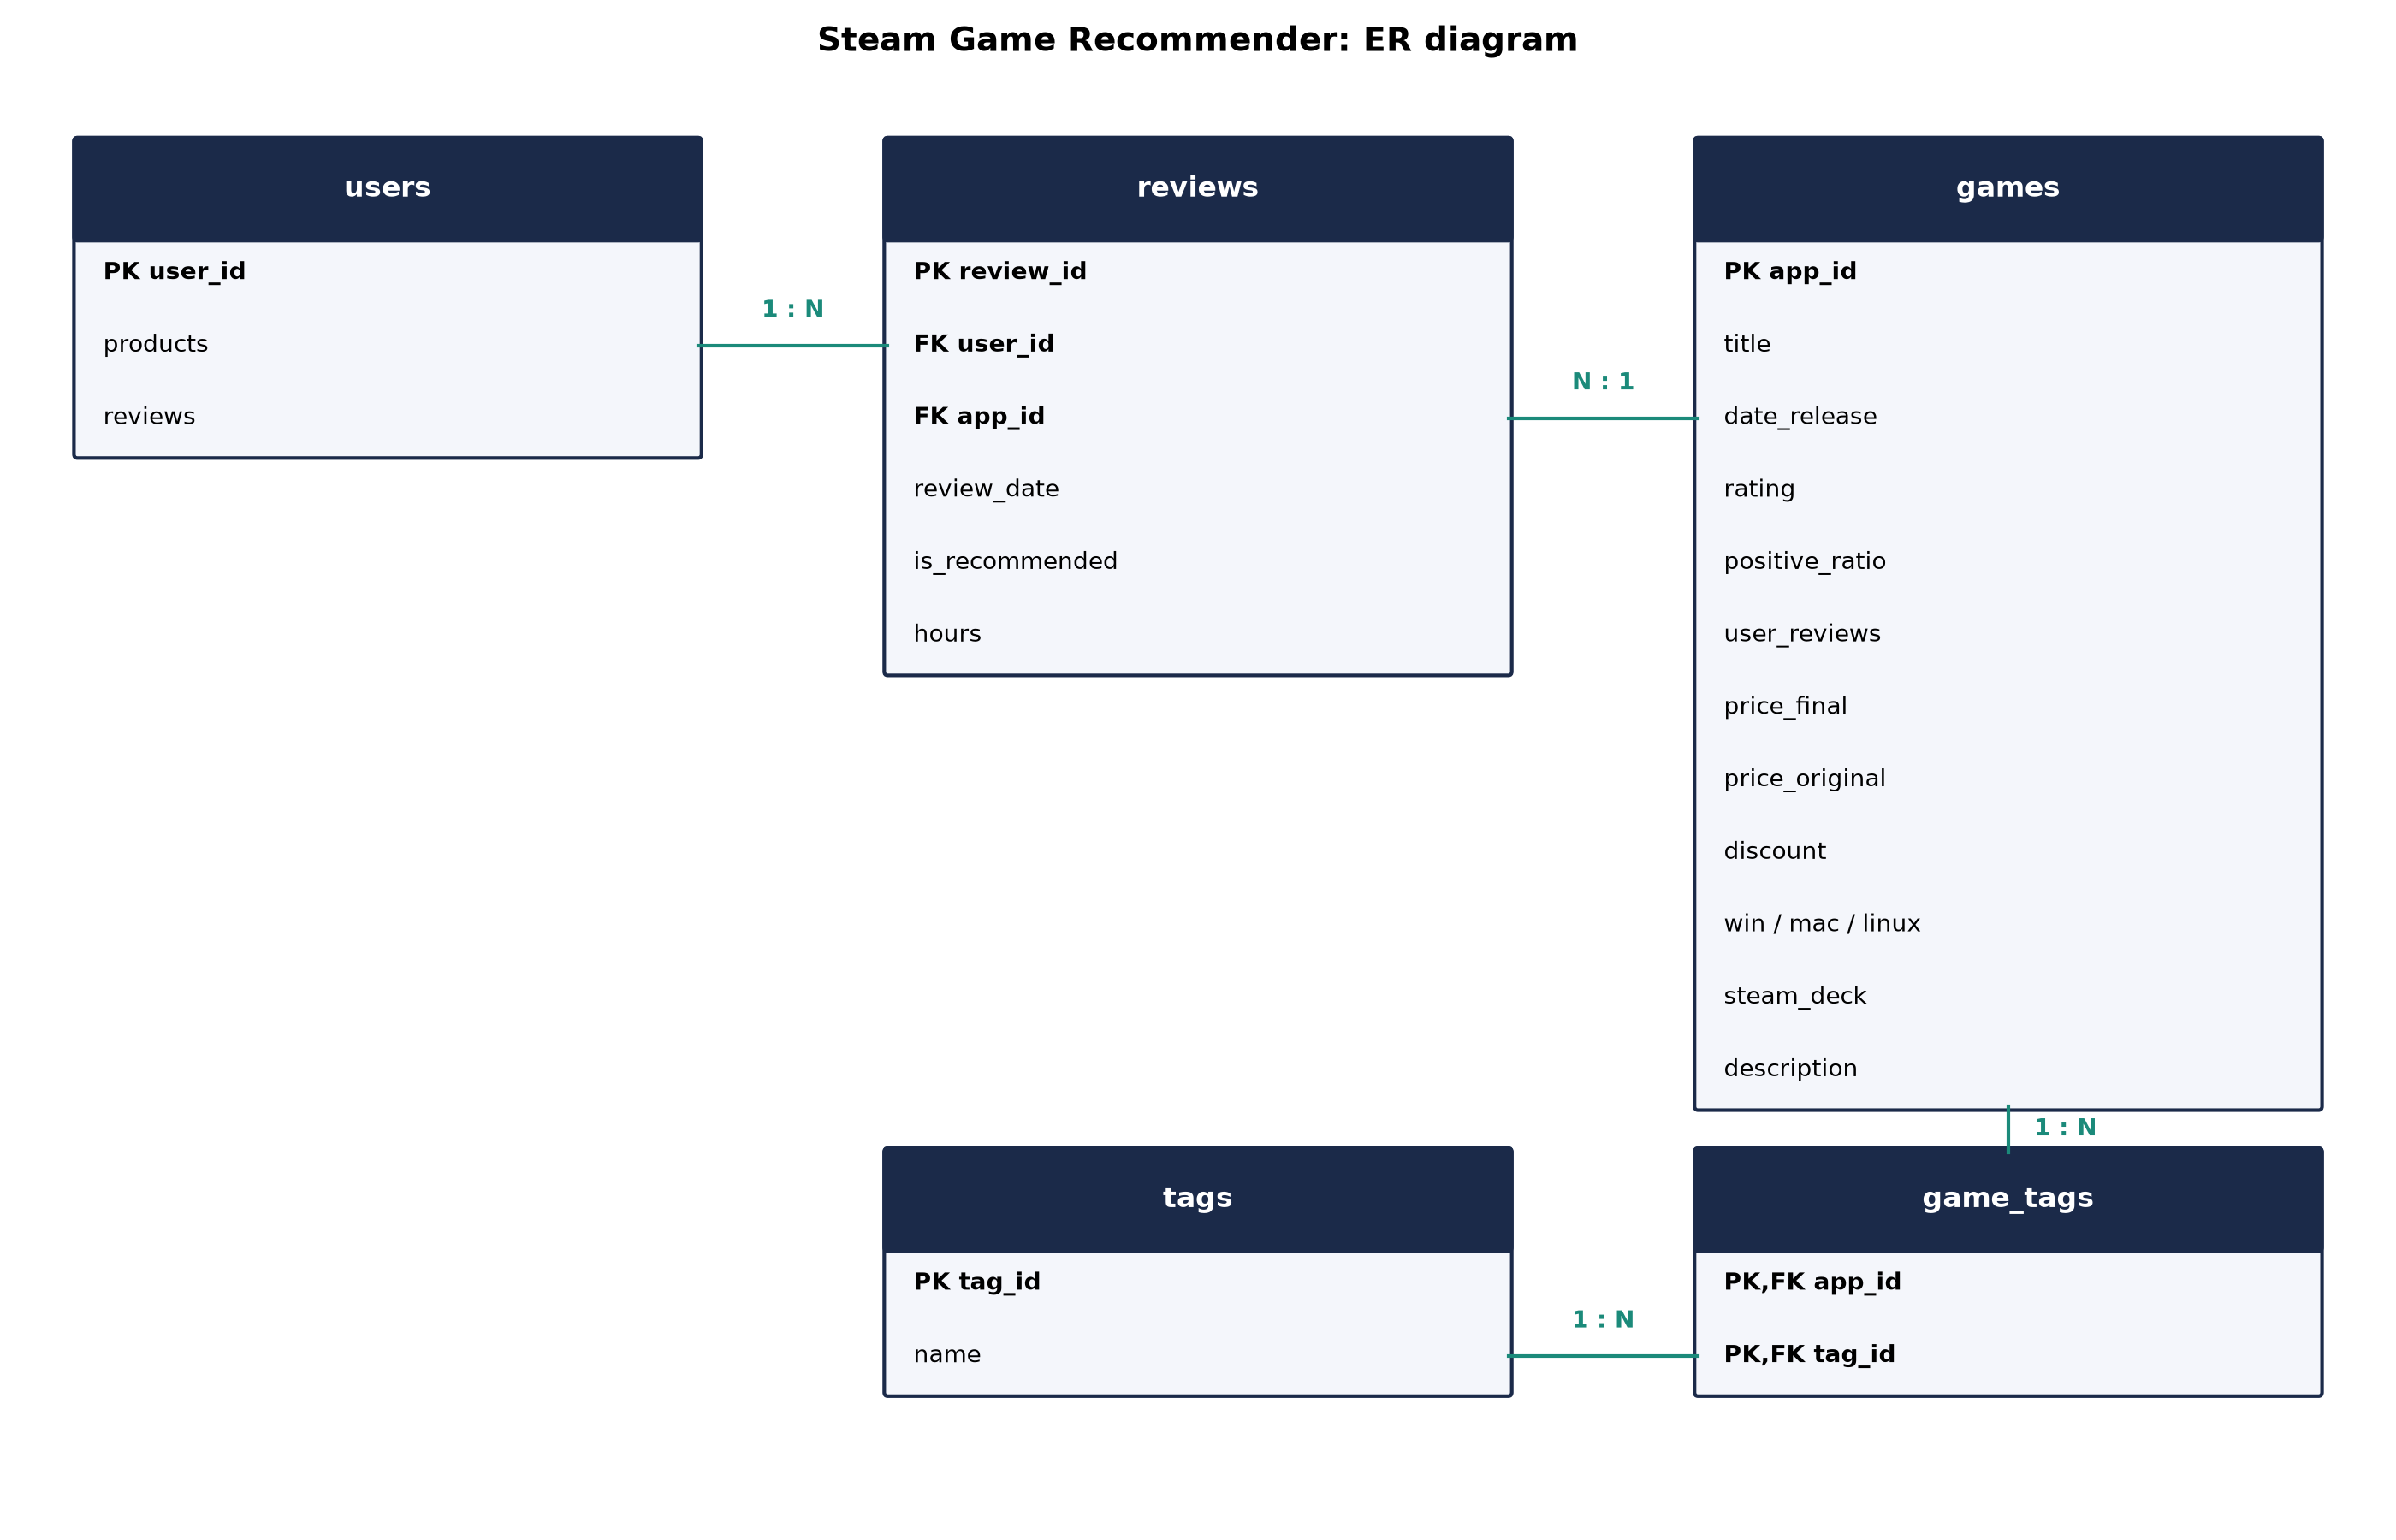

In [24]:
db.draw_er_diagram()
Image(str(db.DATABASE_DIR / "er_diagram.png"))

In [25]:
db_info = db.create_database(source="full")
db_info

reviews part 1/16: 2,582,781 rows
reviews part 2/16: 5,163,865 rows
reviews part 3/16: 7,736,644 rows
reviews part 4/16: 10,308,277 rows
reviews part 5/16: 12,883,392 rows
reviews part 6/16: 15,454,710 rows
reviews part 7/16: 18,033,254 rows
reviews part 8/16: 20,605,201 rows
reviews part 9/16: 23,170,977 rows
reviews part 10/16: 25,743,041 rows
reviews part 11/16: 28,311,119 rows
reviews part 12/16: 30,885,615 rows
reviews part 13/16: 33,454,924 rows
reviews part 14/16: 36,017,965 rows
reviews part 15/16: 38,587,076 rows
reviews part 16/16: 41,154,773 rows
{'source': 'full', 'db_path': '/Users/alllukaaa/Desktop/AI_programming_final_project/data/steam.db', 'games': 50872, 'tags': 441, 'game_tags': 584215, 'users': 14306064, 'reviews': 41154773, 'foreign_key_violations': 0, 'db_size_mb': 3660.5, 'timings': {'games_users_tags_sec': 19.1, 'reviews_sec': 146.31, 'indexes_sec': 32.38, 'fk_check_sec': 43.33}}


{'source': 'full',
 'db_path': '/Users/alllukaaa/Desktop/AI_programming_final_project/data/steam.db',
 'games': 50872,
 'tags': 441,
 'game_tags': 584215,
 'users': 14306064,
 'reviews': 41154773,
 'foreign_key_violations': 0,
 'db_size_mb': 3660.5,
 'timings': {'games_users_tags_sec': 19.1,
  'reviews_sec': 146.31,
  'indexes_sec': 32.38,
  'fk_check_sec': 43.33}}

In [26]:
list(db.load_queries())

['q01_table_sizes',
 'q02_top20_games_by_reviews',
 'q03_avg_hours_per_game',
 'q04_popular_and_liked_games',
 'q05_activity_by_year',
 'q06_games_above_average_popularity',
 'q07_rank_within_price_category',
 'q08_top_game_each_year',
 'q09_tags_by_positive_share',
 'q10_user_activity_segments']

In [27]:
sql_results = db.run_all_queries()

q01_table_sizes: 5 rows, 0.31 s
q02_top20_games_by_reviews: 20 rows, 1.29 s
q03_avg_hours_per_game: 20 rows, 16.28 s
q04_popular_and_liked_games: 20 rows, 16.27 s
q05_activity_by_year: 13 rows, 65.7 s
q06_games_above_average_popularity: 20 rows, 0.71 s
q07_rank_within_price_category: 20 rows, 1.41 s
q08_top_game_each_year: 13 rows, 19.17 s
q09_tags_by_positive_share: 20 rows, 15.88 s
q10_user_activity_segments: 5 rows, 3.98 s


In [28]:
sql_results["q01_table_sizes"]

,table_name,n_rows
0,games,50872
1,users,14306064
2,reviews,41154773
3,tags,441
4,game_tags,584215


In [29]:
sql_results["q02_top20_games_by_reviews"]

,app_id,title,review_count
0,440,Team Fortress 2,319491
1,252490,Rust,270684
2,1091500,Cyberpunk 2077,226414
3,730,Counter-Strike: Global Offensive,219737
4,570,Dota 2,216914
5,444090,Paladins®,204176
6,292030,The Witcher® 3: Wild Hunt,204166
7,377160,Fallout 4,196789
8,374320,DARK SOULS™ III,190157
9,431960,Wallpaper Engine,190129


In [30]:
sql_results["q03_avg_hours_per_game"]

,app_id,title,review_count,avg_hours,max_hours
0,570,Dota 2,216914,429.1,999.9
1,730,Counter-Strike: Global Offensive,219737,429.0,999.9
2,236850,Europa Universalis IV,44974,396.7,999.9
3,39210,FINAL FANTASY XIV Online,52488,373.6,999.9
4,394360,Hearts of Iron IV,143187,370.8,999.9
5,1009850,OVR Advanced Settings,1204,364.7,999.5
6,230410,Warframe,127812,363.4,999.9
7,359550,Tom Clancy's Rainbow Six® Siege,189603,361.0,999.9
8,1147690,NGU IDLE,4857,356.6,999.8
9,381210,Dead by Daylight,80582,347.0,999.9


In [31]:
sql_results["q04_popular_and_liked_games"]

,app_id,title,review_count,positive_pct
0,440,Team Fortress 2,319491,92.3
1,252490,Rust,270684,83.6
2,730,Counter-Strike: Global Offensive,219737,84.8
3,570,Dota 2,216914,79.2
4,444090,Paladins®,204176,84.0
5,292030,The Witcher® 3: Wild Hunt,204166,94.6
6,377160,Fallout 4,196789,81.6
7,374320,DARK SOULS™ III,190157,92.9
8,431960,Wallpaper Engine,190129,98.2
9,359550,Tom Clancy's Rainbow Six® Siege,189603,81.9


In [32]:
sql_results["q05_activity_by_year"]

,year,review_count,active_users,positive_pct
0,2010,12201,7946,97.4
1,2011,71546,40058,96.5
2,2012,101726,61891,96.0
3,2013,335335,213743,93.1
4,2014,1143155,679994,88.0
5,2015,1477096,824048,83.5
6,2016,2226413,1282516,83.5
7,2017,2834442,1569849,82.2
8,2018,2845219,1602871,81.3
9,2019,4226832,2520439,86.8


In [33]:
sql_results["q06_games_above_average_popularity"]

,title,review_count,avg_reviews_per_game
0,Team Fortress 2,319491,1094.3
1,Rust,270684,1094.3
2,Cyberpunk 2077,226414,1094.3
3,Counter-Strike: Global Offensive,219737,1094.3
4,Dota 2,216914,1094.3
5,Paladins®,204176,1094.3
6,The Witcher® 3: Wild Hunt,204166,1094.3
7,Fallout 4,196789,1094.3
8,DARK SOULS™ III,190157,1094.3
9,Wallpaper Engine,190129,1094.3


In [34]:
sql_results["q07_rank_within_price_category"]

,price_category,rank_in_category,title,price_final,review_count
0,1 Free,1,Team Fortress 2,0.00,319491
1,1 Free,2,Dota 2,0.00,216914
2,1 Free,3,Paladins®,0.00,204176
3,1 Free,4,Destiny 2,0.00,185527
4,1 Free,5,Grand Theft Auto V,0.00,163909
5,2 Under 10,1,Wallpaper Engine,4.00,190129
6,2 Under 10,2,Among Us,3.00,171665
7,2 Under 10,3,Sid Meier’s Civilization® VI,6.00,153964
8,2 Under 10,4,Tomb Raider,2.99,107789
9,2 Under 10,5,Counter-Strike: Source,9.99,85502


In [35]:
sql_results["q08_top_game_each_year"]

,year,title,review_count
0,2010,Killing Floor,514
1,2011,Portal 2,2623
2,2012,Team Fortress 2,2613
3,2013,Dota 2,6441
4,2014,Unturned,20235
5,2015,PAYDAY 2,23220
6,2016,No Man's Sky,48938
7,2017,Paladins®,44165
8,2018,Tom Clancy's Rainbow Six® Siege,31676
9,2019,Destiny 2,59058


In [36]:
sql_results["q09_tags_by_positive_share"]

,tag,n_games,review_count,positive_pct
0,Singleplayer,19538,16106604,86.0
1,Action,16190,13892557,84.3
2,Adventure,16318,12426661,85.0
3,Multiplayer,5576,10358416,83.1
4,Indie,23480,10129693,85.8
5,Atmospheric,7468,8612578,87.2
6,Story Rich,6275,7023844,87.4
7,Great Soundtrack,3612,6800433,89.3
8,Open World,2991,6214696,82.7
9,Co-op,2658,6131299,82.2


In [37]:
sql_results["q10_user_activity_segments"]

,reviews_per_user,n_users,n_reviews
0,1,7573027,7573027
1,2-4,4297202,11137458
2,5-9,1230021,7843903
3,10-49,643649,11160624
4,50+,37160,3439761


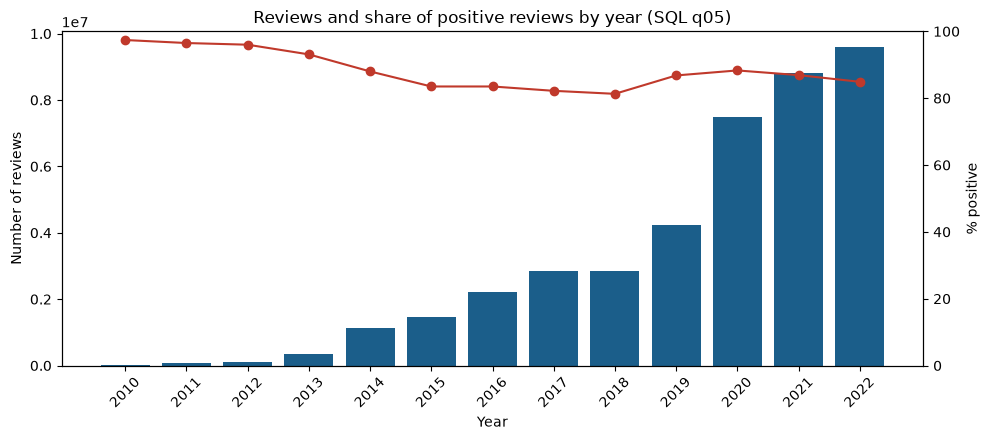

In [38]:
by_year = sql_results["q05_activity_by_year"]
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(by_year["year"], by_year["review_count"], color="#1b5e8a")
ax1.set_xlabel("Year")
ax1.set_ylabel("Number of reviews")
ax2 = ax1.twinx()
ax2.plot(by_year["year"], by_year["positive_pct"], color="#c0392b", marker="o")
ax2.set_ylabel("% positive")
ax2.set_ylim(0, 100)
ax1.set_title("Reviews and share of positive reviews by year (SQL q05)")
ax1.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "figures" / "sql_activity_by_year.png", dpi=200)

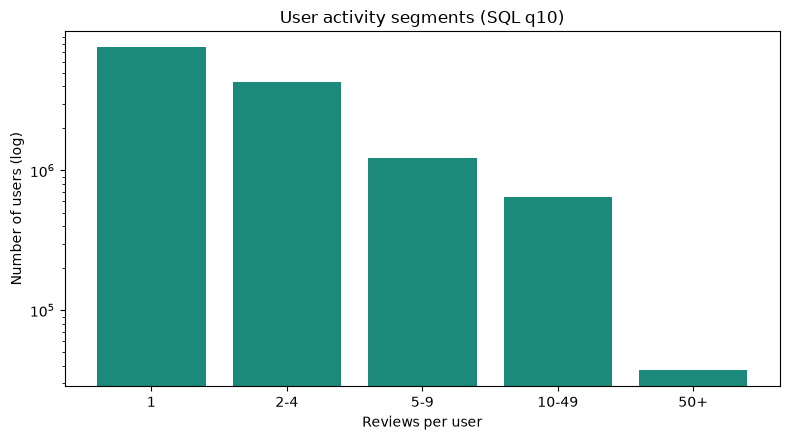

In [39]:
segments = sql_results["q10_user_activity_segments"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(segments["reviews_per_user"], segments["n_users"], color="#1b8a7a")
ax.set_yscale("log")
ax.set_xlabel("Reviews per user")
ax.set_ylabel("Number of users (log)")
ax.set_title("User activity segments (SQL q10)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "figures" / "sql_user_segments.png", dpi=200)

In [40]:
reviews_eda, games_eda = eda.load_eda_data("full")
print(reviews_eda.shape)

(41154773, 5)


{'top_games': {'Team Fortress 2': 319491,
  'Rust': 270684,
  'Cyberpunk 2077': 226414,
  'Counter-Strike: Global Offensive': 219737,
  'Dota 2': 216914,
  'Paladins®': 204176,
  'The Witcher® 3: Wild Hunt': 204166,
  'Fallout 4': 196789,
  'DARK SOULS™ III': 190157,
  'Wallpaper Engine': 190129,
  "Tom Clancy's Rainbow Six® Siege": 189603,
  'Destiny 2': 185527,
  'Left 4 Dead 2': 179684,
  'Euro Truck Simulator 2': 179407,
  "No Man's Sky": 171816,
  'Among Us': 171665,
  'Grand Theft Auto V': 163909,
  'ARK: Survival Evolved': 159736,
  'Brawlhalla': 159720,
  'Borderlands 2': 158945},
 'top20_share_of_reviews': 0.0962}

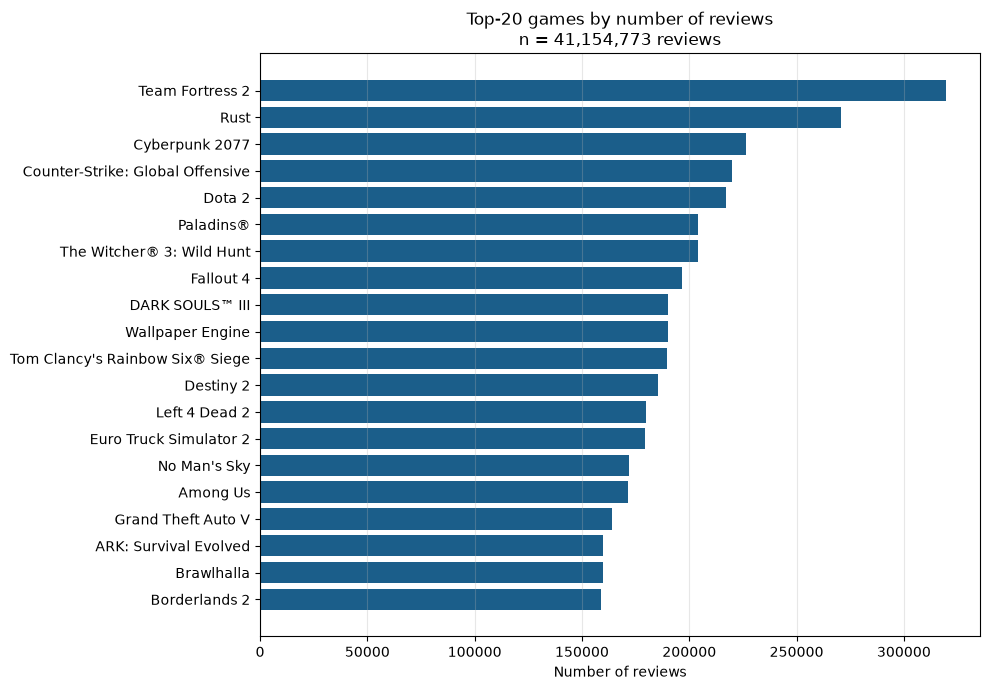

In [41]:
fig, top_stats = eda.plot_top_games(reviews_eda, games_eda)
top_stats

{'games_with_reviews': 37610,
 'top1pct_games_share': 0.5561,
 'top10pct_games_share': 0.9159,
 'games_with_lt_10_reviews': 6384,
 'median_reviews_per_game': 39.0}

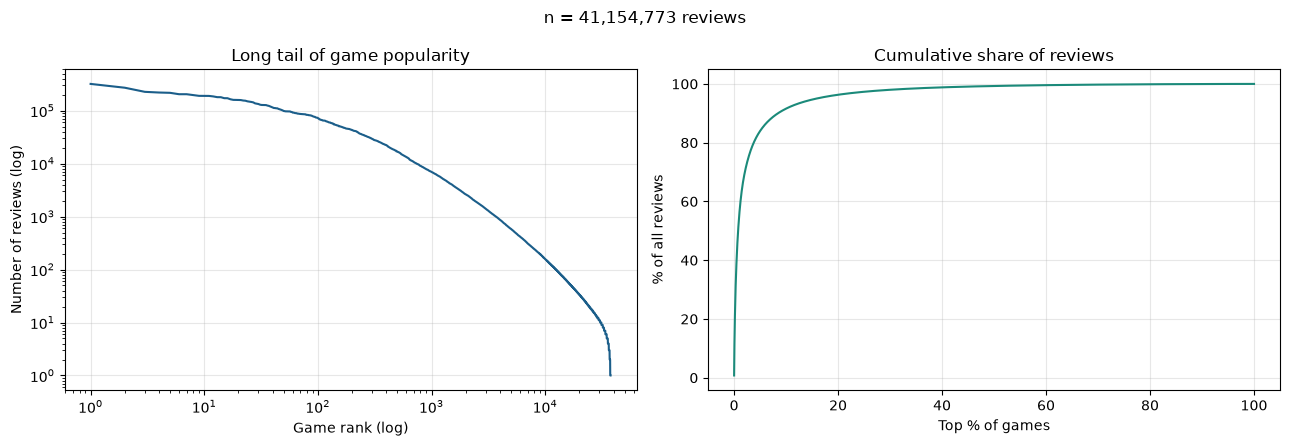

In [42]:
fig, tail_stats = eda.plot_long_tail(reviews_eda)
tail_stats

{'n_users': 13781059,
 'user_median_reviews': 1.0,
 'user_mean_reviews': 2.99,
 'users_with_1_review_share': 0.5495,
 'users_with_5plus_reviews_share': 0.1387,
 'n_games': 37610,
 'game_median_reviews': 39.0,
 'game_mean_reviews': 1094.25}

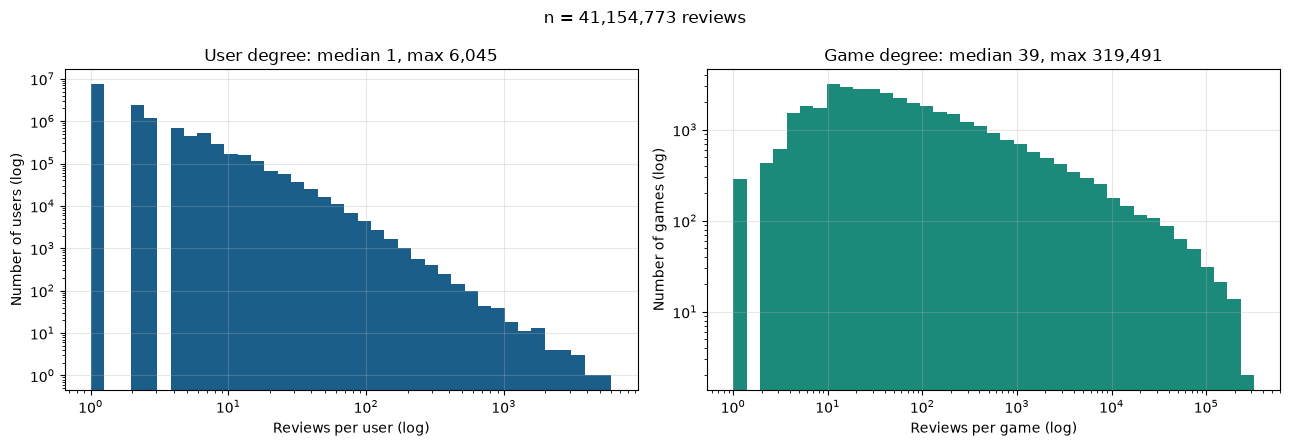

In [43]:
fig, degree_stats = eda.plot_degree_distributions(reviews_eda)
degree_stats

{'median_hours': 27.3,
 'mean_hours': 100.6,
 'p90_hours': 304.0,
 'max_hours': 1000.0,
 'zero_hours_share': 0.0043,
 'share_at_max': 0.0,
 'median_hours_positive': 30.3,
 'median_hours_negative': 11.1}

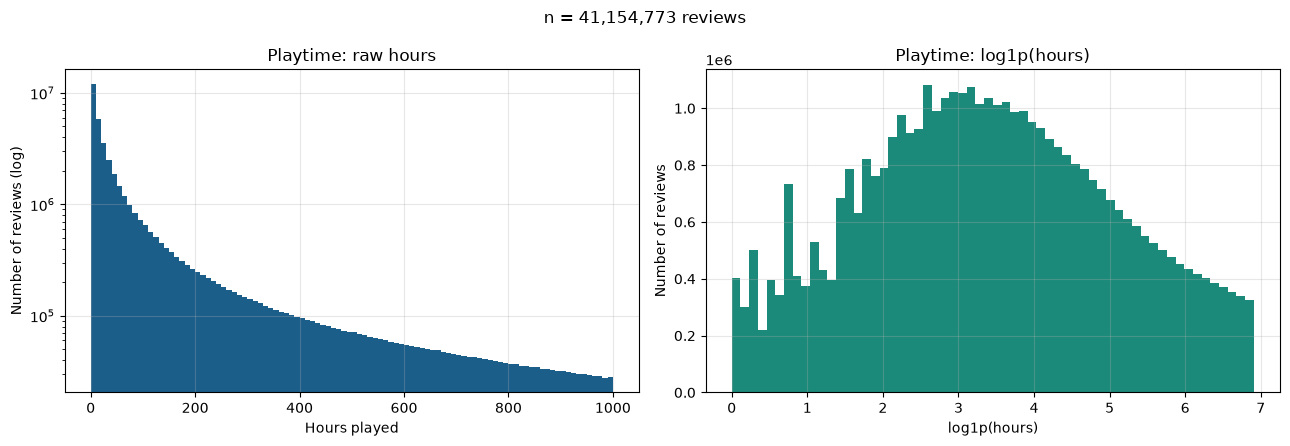

In [44]:
fig, hours_stats = eda.plot_hours(reviews_eda)
hours_stats

{'positive_share': 0.8578,
 'peak_month': '2022-11',
 'peak_month_reviews': 1282247,
 'reviews_by_year': {'2010': 12201,
  '2011': 71546,
  '2012': 101726,
  '2013': 335335,
  '2014': 1143155,
  '2015': 1477096,
  '2016': 2226413,
  '2017': 2834442,
  '2018': 2845219,
  '2019': 4226832,
  '2020': 7488439,
  '2021': 8802848,
  '2022': 9589521},
 'positive_share_by_year': {'2010': 0.9739,
  '2011': 0.965,
  '2012': 0.9599,
  '2013': 0.9307,
  '2014': 0.8796,
  '2015': 0.8347,
  '2016': 0.8349,
  '2017': 0.8221,
  '2018': 0.8132,
  '2019': 0.8682,
  '2020': 0.8834,
  '2021': 0.8688,
  '2022': 0.8488}}

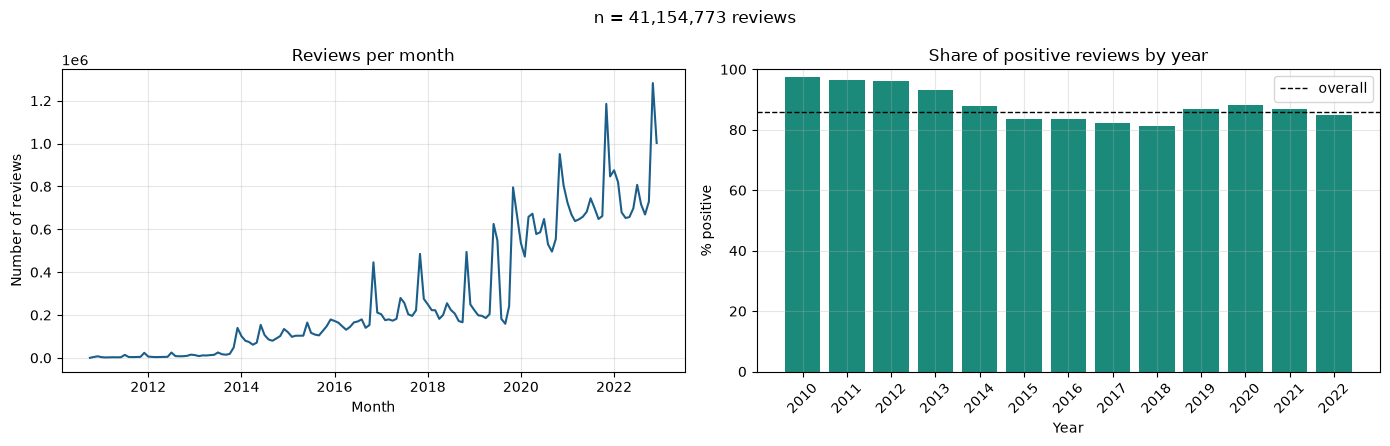

In [45]:
fig, time_stats = eda.plot_reviews_over_time(reviews_eda)
time_stats

In [46]:
sparsity_stats = eda.sparsity_summary(reviews_eda)
sparsity_stats

{'n_users': 13781059,
 'n_games': 37610,
 'interactions': 41154773,
 'density': 7.940251986110308e-05,
 'sparsity': 0.999920597480139,
 'dense_matrix_gb_float32': 1930.8}

In [47]:
%pip install plotly


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [48]:
interactive_fig = eda.plot_interactive_games(reviews_eda, games_eda)
interactive_fig.show()

In [49]:
eda_summary = {"rows": len(reviews_eda), "top_games": top_stats, "long_tail": tail_stats,
               "degrees": degree_stats, "hours": hours_stats, "time": time_stats,
               "sparsity": sparsity_stats}
save_json(eda_summary, RESULTS_DIR / "eda_summary.json")

PosixPath('/Users/alllukaaa/Desktop/AI_programming_final_project/results/eda_summary.json')

In [50]:
#positive feedback

print(sample["is_recommended"].value_counts())
print(sample["hours"].describe())
print(sample["date"].min(), sample["date"].max())

is_recommended
True     506312
False     89638
Name: count, dtype: int64
count    595950.000000
mean         74.323723
std         146.462662
min           0.000000
25%           5.500000
50%          18.900000
75%          65.099998
max         999.900024
Name: hours, dtype: float64
2010-10-16 00:00:00 2022-12-31 00:00:00


In [ ]:
#temporal split

sample = pd.read_parquet(ROOT / "data/processed/sample_reviews.parquet")

from src.preprocessing import temporal_split

train, val, test = temporal_split(sample)

print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

print("Train period:", train["date"].min(), train["date"].max())
print("Validation period:", val["date"].min(), val["date"].max())
print("Test period:", test["date"].min(), test["date"].max())

Train: (416892, 6)
Validation: (59746, 6)
Test: (119312, 6)
Train period: 2010-10-16 00:00:00 2021-07-13 00:00:00
Validation period: 2021-07-14 00:00:00 2022-01-01 00:00:00
Test period: 2022-01-02 00:00:00 2022-12-31 00:00:00


In [53]:
train_users = set(train["user_id"])

positive_test = test[test["is_recommended"] == True]
evaluation_users = train_users & set(positive_test["user_id"])

print("Evaluation users:", len(evaluation_users))

train_games = set(train["app_id"])
test_games = set(test["app_id"])

cold_start_games = test_games - train_games

print("Cold-start games:", len(cold_start_games))

Evaluation users: 26936
Cold-start games: 4215


In [54]:
out = ROOT / "data/processed"

train.to_parquet(out / "train.parquet", index=False)
val.to_parquet(out / "val.parquet", index=False)
test.to_parquet(out / "test.parquet", index=False)

print("temporal split saved")

temporal split saved


In [10]:
#sparse user-item matrix
mat, u_map, i_map = pp.build_user_item_matrix(train)

print("Matrix shape:", mat.shape)
print("Non-zero elements:", mat.nnz)

Matrix shape: (46195, 16344)
Non-zero elements: 354652
